# v2 디테일 분석 — baseline 대비 변화량

핸드오프 4-1 디테일 분석 4가지:
- A. 환경별 정답률 변화
- B. 핀 클래스 hallucination 잔존 여부
- C. 1개 알약 케이스 정답률
- D. 알약 개수별 정답률

비교 대상:
- baseline — synthetic_combined 7200, imgsz 640, batch 16, Top-1 29.8% (e15)
- v2 — synthetic_v2 + K-code, imgsz 1280, batch 16, Top-1 31.9% (e14)

## 셋업 — 두 결과 JSON 존재 확인 + 메타 비교

In [2]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

ROOT = Path(r"D:\pill_detection")

# baseline — 진단 노트북에서 사용한 JSON
RESULTS_BASELINE = ROOT / "eval" / "rtmdet_tiny_synth_e15_seed100_results.json"

# v2 (학습 노트북 trainv2 산출물) — Drive에서 다운로드
RESULTS_V2 = ROOT / "eval" / "rtmdet_tiny_synth_e14_seed100_results.json"

TEST_LABELS = ROOT / "eval" / "test_labels" / "test_labels"

# 존재 확인
print("=" * 70)
print("결과 JSON 존재 확인")
print("=" * 70)
for label, p in [("baseline", RESULTS_BASELINE), ("v2", RESULTS_V2)]:
    if p.exists():
        size_mb = p.stat().st_size / 1024 / 1024
        print(f"  {label:10s} OK  ({size_mb:.2f} MB)  →  {p}")
    else:
        print(f"  {label:10s} 없음  →  {p}")

print(f"\ntest_labels: {TEST_LABELS.exists()} "
      f"({len(list(TEST_LABELS.glob('*'))) if TEST_LABELS.exists() else 0} files)")

assert RESULTS_BASELINE.exists(), "baseline JSON 없음"
assert RESULTS_V2.exists(), "v2 JSON 없음 — Drive에서 다운로드 필요"

# 메타 비교
print("\n" + "=" * 70)
print("실험 메타 비교")
print("=" * 70)
metas = {}
for label, p in [("baseline", RESULTS_BASELINE), ("v2", RESULTS_V2)]:
    with open(p, "r", encoding="utf-8") as f:
        r = json.load(f)
    metas[label] = r
    print(f"\n[{label}]")
    for k in ['exp_name', 'best_epoch', 'conf_threshold', 'nms_iou',
              'num_images', 'num_gt_bboxes', 'eval_version', 'seed']:
        if k in r:
            print(f"  {k}: {r[k]}")

결과 JSON 존재 확인
  baseline   OK  (0.14 MB)  →  D:\pill_detection\eval\rtmdet_tiny_synth_e15_seed100_results.json
  v2         OK  (0.08 MB)  →  D:\pill_detection\eval\rtmdet_tiny_synth_e14_seed100_results.json

test_labels: True (33 files)

실험 메타 비교

[baseline]
  exp_name: rtmdet_tiny_synth_e15_seed100
  best_epoch: 15
  conf_threshold: 0.05
  nms_iou: 0.5
  num_images: 33
  num_gt_bboxes: 47
  eval_version: v4
  seed: 100

[v2]
  exp_name: rtmdet_tiny_synth_e14_seed100
  best_epoch: 14
  conf_threshold: 0.05
  nms_iou: 0.5
  num_images: 33
  num_gt_bboxes: 47
  eval_version: v4
  seed: 100


## GT ↔ 예측 매칭 (IoU 0.5)

진단 노트북 셀 7과 동일 로직:
- 각 GT마다 IoU 최대 예측 1개 매칭 (greedy)
- 한 예측은 한 GT에만 매칭
- IoU 0.5 통일 (진단 시 0.3과 거의 동일 확인됨)

verdict 판정:
- `top1`: 매칭된 예측 top3[0] = GT dl_name
- `top3`: top3 안에 정답 있음
- `det_only`: 매칭됐지만 top3 안에 정답 없음
- `det_fail`: 매칭되는 예측 없음

In [3]:
def iou_xyxy(box1, box2):
    """두 xyxy 박스의 IoU"""
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])
    if x2 <= x1 or y2 <= y1:
        return 0.0
    inter = (x2 - x1) * (y2 - y1)
    a1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    a2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    union = a1 + a2 - inter
    return inter / union if union > 0 else 0.0


def match_gt_to_pred(gt_bboxes, predictions, iou_thr):
    """각 GT마다 IoU 최대 예측 1개 매칭 (greedy, IoU 높은 쌍 우선)"""
    n_gt = len(gt_bboxes)
    n_pred = len(predictions)
    iou_mat = np.zeros((n_gt, n_pred))
    for i, gt in enumerate(gt_bboxes):
        for j, pred in enumerate(predictions):
            iou_mat[i, j] = iou_xyxy(gt['bbox'], pred['bbox'])

    gt_matches = []
    used_pred = set()
    used_gt = set()
    pairs = [(iou_mat[i, j], i, j) for i in range(n_gt) for j in range(n_pred)]
    pairs.sort(reverse=True)

    for iou, i, j in pairs:
        if iou < iou_thr:
            break
        if i in used_gt or j in used_pred:
            continue
        used_gt.add(i)
        used_pred.add(j)

        gt_name = gt_bboxes[i]['dl_name']
        top3_names = predictions[j].get('top3_class_name', [])
        top3_conf = predictions[j].get('top3_confidence', [])

        if len(top3_names) > 0 and top3_names[0] == gt_name:
            verdict = 'top1'
        elif gt_name in top3_names:
            verdict = 'top3'
        else:
            verdict = 'det_only'

        gt_matches.append({
            'gt_idx': i, 'pred_idx': j, 'iou': iou,
            'gt_name': gt_name, 'top3_names': top3_names, 'top3_conf': top3_conf,
            'verdict': verdict
        })

    for i in range(n_gt):
        if i not in used_gt:
            gt_matches.append({
                'gt_idx': i, 'pred_idx': None, 'iou': 0.0,
                'gt_name': gt_bboxes[i]['dl_name'],
                'top3_names': [], 'top3_conf': [],
                'verdict': 'det_fail'
            })

    unmatched_pred_idx = [j for j in range(n_pred) if j not in used_pred]
    return gt_matches, unmatched_pred_idx


def run_matching(results_obj, iou_thr=0.5):
    """results JSON 객체 받아서 매칭 → DataFrame + 오탐 카운트"""
    rows = []
    fp_count = 0
    for img_data in results_obj['results']:
        fname = img_data['filename']
        gts = img_data['gt_bboxes']
        preds = img_data['predictions']
        matches, unmatched_preds = match_gt_to_pred(gts, preds, iou_thr)
        fp_count += len(unmatched_preds)
        for m in matches:
            rows.append({
                'filename': fname,
                'gt_idx': m['gt_idx'],
                'gt_name': m['gt_name'],
                'pred_idx': m['pred_idx'],
                'iou': m['iou'],
                'verdict': m['verdict'],
                'top1_pred': m['top3_names'][0] if m['top3_names'] else None,
                'top3_names': m['top3_names'],
                'top1_conf': m['top3_conf'][0] if m['top3_conf'] else None,
            })
    return pd.DataFrame(rows), fp_count


# 두 JSON 모두 매칭
df_baseline, fp_baseline = run_matching(metas['baseline'], iou_thr=0.5)
df_v2,       fp_v2       = run_matching(metas['v2'],       iou_thr=0.5)

print(f"baseline: {len(df_baseline)} GT 매칭 / FP {fp_baseline}")
print(f"v2      : {len(df_v2)} GT 매칭 / FP {fp_v2}")

# 두 df의 GT 순서 동일성 확인 (filename + gt_idx 기준)
merged_check = df_baseline[['filename', 'gt_idx', 'gt_name']].merge(
    df_v2[['filename', 'gt_idx', 'gt_name']],
    on=['filename', 'gt_idx'], suffixes=('_b', '_v2')
)
mismatch = (merged_check['gt_name_b'] != merged_check['gt_name_v2']).sum()
print(f"\nGT 순서 동일성: {len(merged_check)}/{len(df_baseline)} 매치, gt_name 불일치 {mismatch}건")
assert mismatch == 0, "두 JSON의 GT 순서 어긋남"

baseline: 47 GT 매칭 / FP 259
v2      : 47 GT 매칭 / FP 100

GT 순서 동일성: 47/47 매치, gt_name 불일치 0건


## 0번 — 전체 verdict 분포 비교 (변화량 표)

baseline 기준값 (진단 노트북):
- Top-1 14/47 (29.8%) / Top-3 19/47 (40.4%) / Detection 45/47 (95.7%) / FP 259

v2 기준값 (HANDOFF 43):
- Top-1 15/47 (31.9%) / Top-3 25/47 (53.2%) / Detection 45/47 (95.7%) / FP 100

본 셀에서 두 기준값 자체검증 + 변화량 표 출력.

In [5]:
def summarize(df, fp):
    n = len(df)
    n_top1 = (df['verdict'] == 'top1').sum()
    n_top3 = df['verdict'].isin(['top1', 'top3']).sum()
    n_det  = df['verdict'].isin(['top1', 'top3', 'det_only']).sum()
    return {
        'top1': n_top1, 'top3': n_top3, 'det': n_det, 'n': n, 'fp': fp,
        'top1_pct': n_top1 / n * 100,
        'top3_pct': n_top3 / n * 100,
        'det_pct':  n_det / n * 100,
    }


s_b = summarize(df_baseline, fp_baseline)
s_v = summarize(df_v2, fp_v2)

print("=" * 75)
print("verdict 분포 (GT 47 기준)")
print("=" * 75)
vc = pd.DataFrame({
    'baseline': df_baseline['verdict'].value_counts(),
    'v2':       df_v2['verdict'].value_counts(),
}).fillna(0).astype(int)
vc = vc.reindex(['top1', 'top3', 'det_only', 'det_fail'], fill_value=0)
vc['Δ (v2-baseline)'] = vc['v2'] - vc['baseline']
print(vc)

print("\n" + "=" * 75)
print("핵심 지표 변화")
print("=" * 75)
def fmt_pp(b, v):
    diff = v - b
    sign = '+' if diff >= 0 else ''
    return f"{b:5.1f}%  →  {v:5.1f}%   ({sign}{diff:.1f}pp)"

print(f"  Top-1     : {fmt_pp(s_b['top1_pct'], s_v['top1_pct'])}  "
      f"({s_b['top1']}/47 → {s_v['top1']}/47)")
print(f"  Top-3     : {fmt_pp(s_b['top3_pct'], s_v['top3_pct'])}  "
      f"({s_b['top3']}/47 → {s_v['top3']}/47)")
print(f"  Detection : {fmt_pp(s_b['det_pct'], s_v['det_pct'])}  "
      f"({s_b['det']}/47 → {s_v['det']}/47)")
print(f"  FP (오탐) : {s_b['fp']:5d}      →  {s_v['fp']:5d}        "
      f"({s_v['fp'] - s_b['fp']:+d})")

# 기록값 자체검증
print("\n" + "=" * 75)
print("기록값 자체검증 (HANDOFF 1-2)")
print("=" * 75)
expected = {
    'baseline': {'top1': 14, 'top3': 19, 'det': 45, 'fp': 259},
    'v2':       {'top1': 15, 'top3': 25, 'det': 45, 'fp': 100},
}
for label, s in [('baseline', s_b), ('v2', s_v)]:
    e = expected[label]
    ok = (s['top1'] == e['top1'] and s['top3'] == e['top3']
          and s['det'] == e['det'] and s['fp'] == e['fp'])
    mark = '✓' if ok else '✗'
    print(f"  {mark} {label}: 측정 top1={s['top1']} top3={s['top3']} det={s['det']} fp={s['fp']}  "
          f"vs 기록 top1={e['top1']} top3={e['top3']} det={e['det']} fp={e['fp']}")

verdict 분포 (GT 47 기준)
          baseline  v2  Δ (v2-baseline)
verdict                                
top1            14  15                1
top3             5  10                5
det_only        26  20               -6
det_fail         2   2                0

핵심 지표 변화
  Top-1     :  29.8%  →   31.9%   (+2.1pp)  (14/47 → 15/47)
  Top-3     :  40.4%  →   53.2%   (+12.8pp)  (19/47 → 25/47)
  Detection :  95.7%  →   95.7%   (+0.0pp)  (45/47 → 45/47)
  FP (오탐) :   259      →    100        (-159)

기록값 자체검증 (HANDOFF 1-2)
  ✓ baseline: 측정 top1=14 top3=19 det=45 fp=259  vs 기록 top1=14 top3=19 det=45 fp=259
  ✓ v2: 측정 top1=15 top3=25 det=45 fp=100  vs 기록 top1=15 top3=25 det=45 fp=100


## 1번 — GT 페어 매트릭스 (일반화 측정의 핵심)

평균치만으로는 일반화 여부 판단 불가. 같은 GT 47개에 대해
baseline verdict → v2 verdict 페어 매트릭스로 전환을 본다.

분류 규칙 (rank):
- top1 (3) > top3 (2) > det_only (1) > det_fail (0)
- v2 rank > baseline rank: 회복
- v2 rank < baseline rank: 후퇴 (← 일반화 후퇴 신호)
- v2 rank = baseline rank: 유지

검증 항목:
- 후퇴 GT가 있는가? 있다면 어떤 알약/예측인가?
- 두 모델 모두 실패한 GT (어려운 케이스 후보) 는 무엇인가?
- GT 좌표 동일성 (sanity check)

In [7]:
# 0) GT 좌표 동일성 sanity check (gt_name만 본 셀 5 보강)
xy_diffs = []
for ib, iv in zip(metas['baseline']['results'], metas['v2']['results']):
    assert ib['filename'] == iv['filename']
    assert len(ib['gt_bboxes']) == len(iv['gt_bboxes'])
    for gb, gv in zip(ib['gt_bboxes'], iv['gt_bboxes']):
        d = np.array(gb['bbox']) - np.array(gv['bbox'])
        xy_diffs.append(float(np.abs(d).max()))
print(f"GT bbox 좌표 max abs diff (px): {max(xy_diffs):.6f}")
print(f"  → 0 이면 두 JSON의 GT 좌표 완전 동일\n")

# 1) 페어 데이터 만들기
df_pair = df_baseline[['filename', 'gt_idx', 'gt_name', 'verdict', 'top1_pred', 'iou']].merge(
    df_v2[['filename', 'gt_idx', 'verdict', 'top1_pred', 'iou']],
    on=['filename', 'gt_idx'], suffixes=('_b', '_v2')
)
assert len(df_pair) == 47, f"페어 GT 수 {len(df_pair)} ≠ 47"

# 2) verdict 페어 매트릭스
order = ['top1', 'top3', 'det_only', 'det_fail']
mat = pd.crosstab(
    df_pair['verdict_b'], df_pair['verdict_v2'],
    margins=True, margins_name='합계'
).reindex(
    index=order + ['합계'], columns=order + ['합계'], fill_value=0
)
print("=" * 75)
print("baseline (행) → v2 (열) verdict 페어 매트릭스 (47 GT)")
print("=" * 75)
print(mat)

# 3) 변화 분류
rank = {'top1': 3, 'top3': 2, 'det_only': 1, 'det_fail': 0}
def classify(b, v):
    if rank[v] > rank[b]: return '회복'
    if rank[v] < rank[b]: return '후퇴'
    return '유지'
df_pair['change'] = df_pair.apply(
    lambda r: classify(r['verdict_b'], r['verdict_v2']), axis=1
)

print("\n" + "=" * 75)
print("변화 분류")
print("=" * 75)
print(df_pair['change'].value_counts())

# 4) 후퇴 케이스 (있다면 일반화 후퇴 신호)
regression = df_pair[df_pair['change'] == '후퇴']
print("\n" + "=" * 75)
print(f"후퇴 케이스 ({len(regression)}개) — baseline에서 맞췄거나 후보권 안에 있었는데 v2가 떨어뜨린 GT")
print("=" * 75)
if len(regression) > 0:
    print(regression[['filename', 'gt_name', 'verdict_b', 'verdict_v2',
                      'top1_pred_b', 'top1_pred_v2']].to_string(index=False))
else:
    print("  없음")

# 5) 두 모델 모두 실패한 케이스
both_fail = df_pair[
    df_pair['verdict_b'].isin(['det_only', 'det_fail']) &
    df_pair['verdict_v2'].isin(['det_only', 'det_fail'])
]
print("\n" + "=" * 75)
print(f"두 모델 모두 실패 ({len(both_fail)}개) — 어려운 케이스 / 모델 캡 한계 후보")
print("=" * 75)
print(both_fail[['filename', 'gt_name', 'verdict_b', 'verdict_v2',
                 'top1_pred_b', 'top1_pred_v2']].to_string(index=False))

# 6) 회복 케이스
recovery = df_pair[df_pair['change'] == '회복']
print("\n" + "=" * 75)
print(f"회복 케이스 ({len(recovery)}개) — v2 진짜 개선분")
print("=" * 75)
print(recovery[['filename', 'gt_name', 'verdict_b', 'verdict_v2',
                'top1_pred_b', 'top1_pred_v2']].to_string(index=False))

GT bbox 좌표 max abs diff (px): 0.000000
  → 0 이면 두 JSON의 GT 좌표 완전 동일

baseline (행) → v2 (열) verdict 페어 매트릭스 (47 GT)
verdict_v2  top1  top3  det_only  det_fail  합계
verdict_b                                     
top1           9     2         3         0  14
top3           3     1         1         0   5
det_only       3     7        16         0  26
det_fail       0     0         0         2   2
합계            15    10        20         2  47

변화 분류
change
유지    28
회복    13
후퇴     6
Name: count, dtype: int64

후퇴 케이스 (6개) — baseline에서 맞췄거나 후보권 안에 있었는데 v2가 떨어뜨린 GT
            filename         gt_name verdict_b verdict_v2     top1_pred_b            top1_pred_v2
        놀텍정 10mg.png        놀텍정 10mg      top1   det_only        놀텍정 10mg 종근당글리아티린연질캡슐(콜린알포세레이트) 
아보다트연질캡슐 0.5mg_1.png  아보다트연질캡슐 0.5mg      top1       top3  아보다트연질캡슐 0.5mg        바이오탑하이캡슐 150mg/병
  아스피린프로텍트정100mg.png 아스피린프로텍트정 100mg      top1       top3 아스피린프로텍트정 100mg            에어탈정(아세클로페낙)
      엔테론정 150mg.png      엔테론정 150mg      

## 1번 시각화 — 33장 결과 그리드 (baseline vs v2)

진단 노트북 figure 01 패턴 그대로 두 모델에 적용. 박스 색상:
- 초록(lime, 실선) — GT 박스
- 파랑(실선) — top1 (정답)
- 주황(실선) — top3 (후보권 안에 정답)
- 빨강(점선) — det_only (박스는 잡았지만 분류 실패)
- 회색 — det_fail (박스 자체 못 잡음)

같은 33장 같은 순서로 그려서 페어 비교. 시각으로만 검출 가능한 패턴 (박스 위치 미세한 차이, 같은 알약에서 다른 오분류 등) 확인.

저장: D:\pill_detection\analysis\figures_v2_compare\01_grid_baseline.png


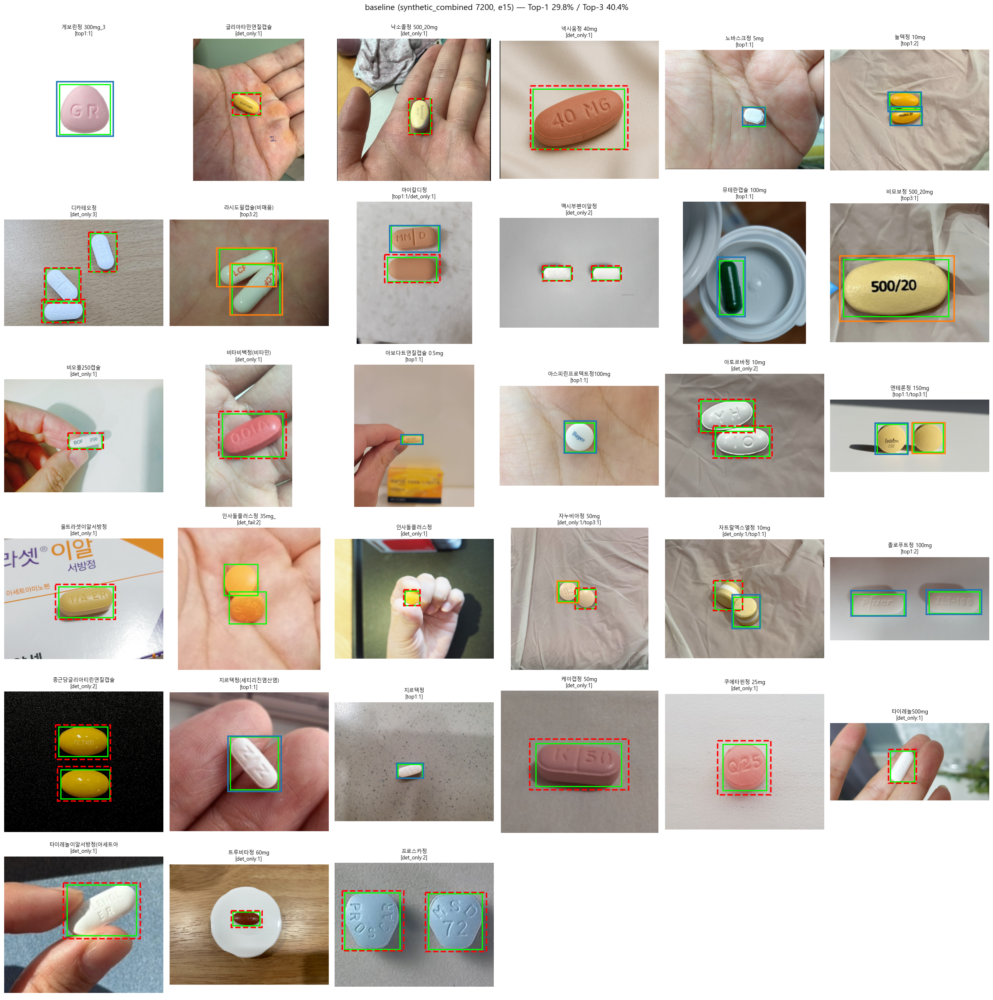

저장: D:\pill_detection\analysis\figures_v2_compare\02_grid_v2.png


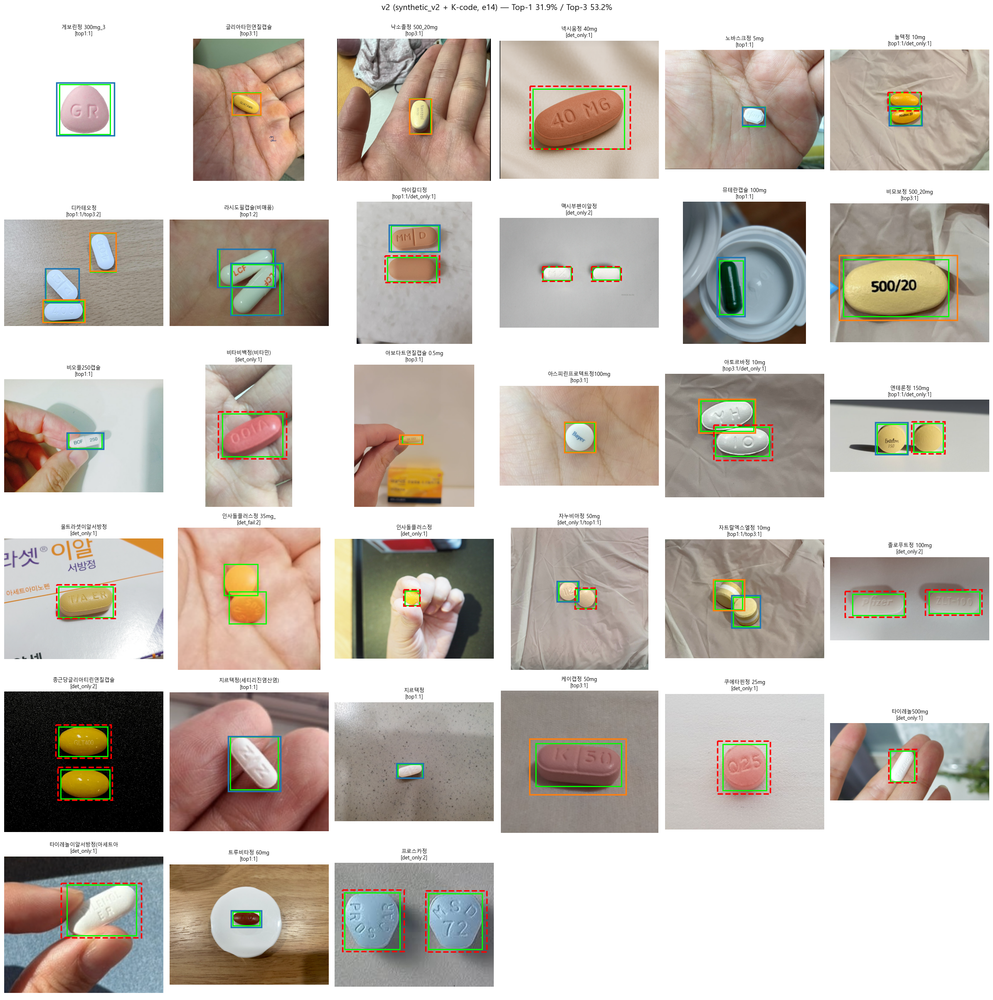


색상 범례:
  lime 초록(실선)= GT 박스
  파랑(실선)     = top1 (정답)
  주황(실선)     = top3 (후보권에 정답)
  빨강(점선)     = det_only (박스 OK, 분류 실패)
  회색           = det_fail (박스 자체 실패)


In [6]:
from matplotlib.patches import Rectangle
import cv2
from collections import Counter

TEST_IMAGES = ROOT / "eval" / "test_images"
assert TEST_IMAGES.exists(), f"test_images 경로 없음: {TEST_IMAGES}"

# verdict 색상 매핑 (진단 노트북 기준)
VERDICT_COLOR = {
    'top1':     'tab:blue',
    'top3':     'tab:orange',
    'det_only': 'red',
    'det_fail': 'gray',
}


def imread_kr(path):
    """한글 경로 호환 imread"""
    return cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)


# 두 모델의 매칭 결과를 filename → DataFrame dict 로 변환
def matches_by_file(df):
    return {f: g for f, g in df.groupby('filename')}

mbf_baseline = matches_by_file(df_baseline)
mbf_v2       = matches_by_file(df_v2)


def draw_grid(results_obj, mbf, title, save_path):
    n_imgs = len(results_obj['results'])
    ncols = 6
    nrows = (n_imgs + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(24, 4 * nrows))
    axes = axes.flatten()

    for ax_idx, img_data in enumerate(results_obj['results']):
        ax = axes[ax_idx]
        fname = img_data['filename']
        img_path = TEST_IMAGES / fname
        if not img_path.exists():
            ax.text(0.5, 0.5, f"파일 없음\n{fname}",
                    ha='center', va='center', transform=ax.transAxes)
            ax.axis('off'); continue
        img = imread_kr(img_path)
        if img is None:
            ax.text(0.5, 0.5, f"로드 실패\n{fname}",
                    ha='center', va='center', transform=ax.transAxes)
            ax.axis('off'); continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        ax.imshow(img)

        # GT 박스 (초록)
        for gt in img_data['gt_bboxes']:
            x1, y1, x2, y2 = gt['bbox']
            ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, linewidth=2,
                                   edgecolor='lime', facecolor='none'))

        # 매칭된 예측 박스 (verdict별 색상)
        file_matches = mbf.get(fname, pd.DataFrame())
        verdicts_this = []
        for _, row in file_matches.iterrows():
            verdicts_this.append(row['verdict'])
            if row['verdict'] == 'det_fail' or row['pred_idx'] is None:
                continue
            pred = img_data['predictions'][int(row['pred_idx'])]
            x1, y1, x2, y2 = pred['bbox']
            color = VERDICT_COLOR[row['verdict']]
            ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, linewidth=2.5,
                                   edgecolor=color, facecolor='none',
                                   linestyle='--' if row['verdict']=='det_only' else '-'))

        c = Counter(verdicts_this)
        v_summary = "/".join(f"{k}:{n}" for k, n in c.items()) if verdicts_this else "-"
        short_name = fname.replace('.png', '')[:14]
        ax.set_title(f"{short_name}\n[{v_summary}]", fontsize=9)
        ax.axis('off')

    for i in range(n_imgs, len(axes)):
        axes[i].axis('off')

    plt.suptitle(title, fontsize=14, y=1.00)
    plt.tight_layout()

    out_path = ROOT / "analysis" / "figures_v2_compare" / save_path
    out_path.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(out_path, dpi=120, bbox_inches='tight')
    print(f"저장: {out_path}")
    plt.show()


# baseline 그리드
draw_grid(metas['baseline'], mbf_baseline,
          "baseline (synthetic_combined 7200, e15) — Top-1 29.8% / Top-3 40.4%",
          "01_grid_baseline.png")

# v2 그리드
draw_grid(metas['v2'], mbf_v2,
          "v2 (synthetic_v2 + K-code, e14) — Top-1 31.9% / Top-3 53.2%",
          "02_grid_v2.png")

print("\n색상 범례:")
print("  lime 초록(실선)= GT 박스")
print("  파랑(실선)     = top1 (정답)")
print("  주황(실선)     = top3 (후보권에 정답)")
print("  빨강(점선)     = det_only (박스 OK, 분류 실패)")
print("  회색           = det_fail (박스 자체 실패)")

## 분석 B — 1순위 예측 빈도 분포 비교

baseline 핀 클래스 (Test 등장 0회인데 자주 1순위 예측):
- 엘스테인캡슐(에르도스테인) 23회 / 이가탄에프캡슐 150mg/PTP 14회 / 알바스테인캡슐(에르도스테인) 13회
- 람노스캡슐500mg/병 11회 / 메가파워정 90mg/병 10회 / 카발린캡슐 25mg 9회

검증:
- v2에서 위 6개 빈도 변화 (감소면 처방 효과)
- v2에 새 핀 클래스 (Test 등장 0회 + v2 빈도 ≥ 임계) 등장 여부
- baseline FP 259 → v2 FP 100 감소가 진짜 정확도 개선인지 단순 conf 낮아진 결과인지

대상: 매칭된 예측 + 오탐(FP) 모든 1순위 예측. results JSON의 모든 predictions 순회.

In [8]:
from collections import Counter

# Test 등장 클래스 풀
test_classes = set()
for img_data in metas['baseline']['results']:
    for gt in img_data['gt_bboxes']:
        test_classes.add(gt['dl_name'])
print(f"Test 등장 클래스 수: {len(test_classes)}")

def collect_top1_preds(results_obj):
    """모든 예측의 1순위 클래스 카운트 (매칭 + 오탐 모두)"""
    counter = Counter()
    for img_data in results_obj['results']:
        for pred in img_data['predictions']:
            top3 = pred.get('top3_class_name', [])
            if top3:
                counter[top3[0]] += 1
    return counter

top1_b = collect_top1_preds(metas['baseline'])
top1_v = collect_top1_preds(metas['v2'])

print(f"총 예측 수: baseline={sum(top1_b.values())} / v2={sum(top1_v.values())}")

# baseline 핀 클래스 6개 (진단 노트북 결과)
baseline_pin = {
    '엘스테인캡슐(에르도스테인)', '이가탄에프캡슐 150mg/PTP',
    '알바스테인캡슐(에르도스테인)', '람노스캡슐500mg/병',
    '메가파워정 90mg/병', '카발린캡슐 25mg',
}

# 두 모델 합산 빈도 Top 15 클래스
all_classes = sorted(
    set(top1_b.keys()) | set(top1_v.keys()),
    key=lambda c: -(top1_b[c] + top1_v[c])
)[:15]

print("\n" + "=" * 100)
print(f"{'클래스':45s} {'baseline':>9s} {'v2':>5s} {'Δ':>6s} {'Test':>5s} {'pin_b':>6s}")
print("=" * 100)
for c in all_classes:
    b, v = top1_b.get(c, 0), top1_v.get(c, 0)
    delta = v - b
    in_test = '✓' if c in test_classes else '-'
    is_pin = '✓' if c in baseline_pin else '-'
    sign = '+' if delta >= 0 else ''
    print(f"  {c[:43]:43s} {b:9d} {v:5d} {sign}{delta:5d} {in_test:>5s} {is_pin:>6s}")

# baseline 핀 6개 v2 변화
print("\n" + "=" * 100)
print("baseline 핀 클래스 6개 v2 빈도 변화")
print("=" * 100)
for c in sorted(baseline_pin, key=lambda c: -top1_b.get(c, 0)):
    b, v = top1_b.get(c, 0), top1_v.get(c, 0)
    print(f"  {c[:50]:50s}  baseline={b:3d}  →  v2={v:3d}  ({v-b:+d})")

# v2 새 핀 클래스 후보 (Test 등장 X + v2 빈도 ≥ 5)
print("\n" + "=" * 100)
print("v2 새 핀 클래스 후보 (Test 등장 X + v2 1순위 예측 ≥ 5)")
print("=" * 100)
v2_pin_candidates = sorted(
    [(c, n) for c, n in top1_v.items() if c not in test_classes and n >= 5],
    key=lambda x: -x[1]
)
if v2_pin_candidates:
    for c, n in v2_pin_candidates:
        b = top1_b.get(c, 0)
        is_old_pin = ' (baseline 핀)' if c in baseline_pin else ''
        print(f"  {c[:50]:50s}  v2={n:3d}  baseline={b:3d}  Δ={n-b:+d}{is_old_pin}")
else:
    print("  없음")

Test 등장 클래스 수: 31
총 예측 수: baseline=304 / v2=145

클래스                                            baseline    v2      Δ  Test  pin_b
  엘스테인캡슐(에르도스테인)                                     23     1   -22     -      ✓
  트루비타정 60mg/병                                       18     4   -14     ✓      -
  이가탄에프캡슐 150mg/PTP                                  14     3   -11     -      ✓
  졸로푸트정 100mg                                        12     4    -8     ✓      -
  알바스테인캡슐(에르도스테인)                                    13     0   -13     -      ✓
  프로스카정                                               7     5    -2     -      -
  람노스캡슐500mg/병                                       11     1   -10     -      ✓
  비오플250캡슐 282.5mg                                    7     3    -4     ✓      -
  메가파워정 90mg/병                                       10     0   -10     -      ✓
  카발린캡슐 25mg                                          9     1    -8     -      ✓
  이튼큐정 35mg/PTP                                       3    

## 분석 1번 추가 — 후퇴 6개 케이스 디테일 시각

같은 GT를 baseline은 맞췄는데 v2가 떨어뜨린 6개 케이스.
한 줄에 같은 이미지 두 번 (왼쪽 baseline, 오른쪽 v2):
- 초록 = GT
- 파랑 실선 = top1 / 주황 실선 = top3 / 빨강 점선 = det_only

각 모델의 1순위 예측 클래스명 라벨로 표시.
검증 항목:
- v2의 잘못된 1순위가 새 핀 4개 (에르도스/이튼큐/동화덴스톨/투스딘골드) 또는 PTP 포장 패턴인가
- 박스 위치는 두 모델이 동일한가 (Detection 같은 박스인지)

후퇴 케이스 6개 시각화

저장: D:\pill_detection\analysis\figures_v2_compare\03_regression_cases.png


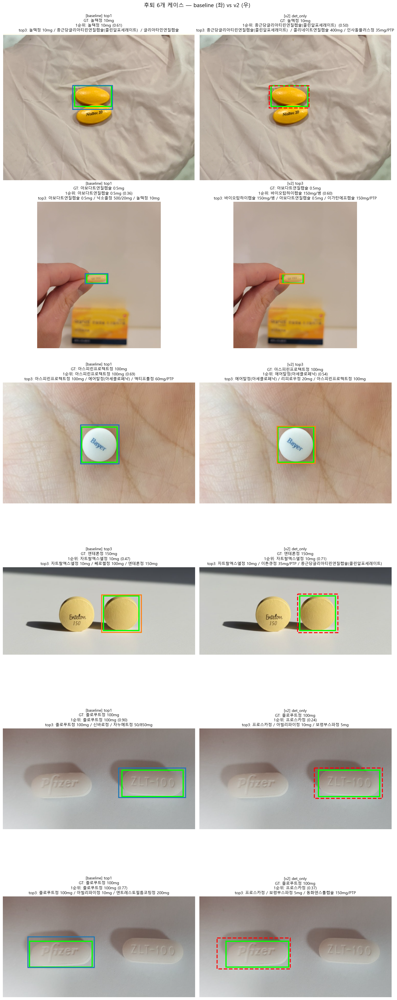


후퇴 케이스 v2 1순위 예측의 패턴 분석
  놀텍정 10mg                  → 종근당글리아티린연질캡슐(콜린알포세레이트)          [특이 패턴 없음]
  아보다트연질캡슐 0.5mg            → 바이오탑하이캡슐 150mg/병                [특이 패턴 없음]
  아스피린프로텍트정 100mg           → 에어탈정(아세클로페낙)                    [특이 패턴 없음]
  엔테론정 150mg                → 자트랄엑스엘정 10mg                    [특이 패턴 없음]
  졸로푸트정 100mg               → 프로스카정                           [특이 패턴 없음]
  졸로푸트정 100mg               → 프로스카정                           [특이 패턴 없음]


In [9]:
regression_cases = df_pair[df_pair['change'] == '후퇴'].reset_index(drop=True)
print(f"후퇴 케이스 {len(regression_cases)}개 시각화\n")

n = len(regression_cases)
fig, axes = plt.subplots(n, 2, figsize=(14, 6 * n))
if n == 1:
    axes = axes.reshape(1, 2)

results_lookup = {
    'baseline': {r['filename']: r for r in metas['baseline']['results']},
    'v2':       {r['filename']: r for r in metas['v2']['results']},
}

for row_idx, case in regression_cases.iterrows():
    fname = case['filename']
    gt_idx = case['gt_idx']
    
    img_path = TEST_IMAGES / fname
    img = imread_kr(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    for col_idx, model_label in enumerate(['baseline', 'v2']):
        ax = axes[row_idx, col_idx]
        ax.imshow(img)
        
        img_data = results_lookup[model_label][fname]
        gt = img_data['gt_bboxes'][gt_idx]
        
        # GT 박스
        x1, y1, x2, y2 = gt['bbox']
        ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, linewidth=3,
                               edgecolor='lime', facecolor='none'))
        
        # 해당 GT 매칭 예측 (같은 gt_idx)
        df_model = df_baseline if model_label == 'baseline' else df_v2
        match_row = df_model[(df_model['filename'] == fname) &
                             (df_model['gt_idx'] == gt_idx)].iloc[0]
        
        verdict = match_row['verdict']
        top1_pred = match_row['top1_pred']
        top1_conf = match_row['top1_conf']
        top3_names = match_row['top3_names']
        
        if verdict != 'det_fail' and match_row['pred_idx'] is not None:
            pred = img_data['predictions'][int(match_row['pred_idx'])]
            px1, py1, px2, py2 = pred['bbox']
            color = VERDICT_COLOR[verdict]
            ax.add_patch(Rectangle((px1, py1), px2-px1, py2-py1, linewidth=2.5,
                                   edgecolor=color, facecolor='none',
                                   linestyle='--' if verdict=='det_only' else '-'))
        
        # 제목: GT명 + verdict + 1순위 예측 + conf
        title = f"[{model_label}] {verdict}\n"
        title += f"GT: {case['gt_name']}\n"
        if top1_pred is not None:
            conf_str = f" ({top1_conf:.2f})" if top1_conf is not None else ""
            title += f"1순위: {top1_pred}{conf_str}"
            if len(top3_names) >= 3:
                title += f"\ntop3: {' / '.join(top3_names[:3])}"
        else:
            title += "(예측 없음)"
        ax.set_title(title, fontsize=10)
        ax.axis('off')

plt.suptitle("후퇴 6개 케이스 — baseline (좌) vs v2 (우)", fontsize=14, y=1.00)
plt.tight_layout()

out_path = ROOT / "analysis" / "figures_v2_compare" / "03_regression_cases.png"
plt.savefig(out_path, dpi=120, bbox_inches='tight')
print(f"저장: {out_path}")
plt.show()

# v2의 1순위 예측이 새 핀 또는 PTP 포장인지 정량 체크
print("\n" + "=" * 75)
print("후퇴 케이스 v2 1순위 예측의 패턴 분석")
print("=" * 75)
new_pin = {'엘도스캡슐(에르도스테인)(수출용)', '이튼큐정 35mg/PTP',
           '동화덴스톨캡슐 150mg/PTP', '투스딘골드캡슐 150mg/PTP'}
for _, case in regression_cases.iterrows():
    pred = case['top1_pred_v2']
    flags = []
    if pred in new_pin:
        flags.append('새 핀')
    if 'PTP' in pred:
        flags.append('PTP 포장')
    if '에르도스테인' in pred or '에르도스' in pred:
        flags.append('에르도스테인 패밀리')
    flag_str = ' / '.join(flags) if flags else '특이 패턴 없음'
    print(f"  {case['gt_name'][:25]:25s} → {pred[:30]:30s}  [{flag_str}]")

## 분석 1번 보강 — conf 분포 변화 + 추가 의심 클래스 검증

후퇴 6개 시각 분석 결과 새로운 의심:
- v2가 전반적으로 conf 낮아진 패턴 (졸로푸트 0.90→0.24)
- 자동 검출 패턴 외 새 핀 후보: 종근당글리아티린, 바이오탑하이, 에어탈정, 자트랄엑스엘정

검증 항목:
- 매칭된 GT의 1순위 conf 분포 (boxplot) baseline vs v2
- 후퇴/회복/유지/공통실패 그룹별 v2-baseline conf 차이
- 추가 의심 클래스 4개의 1순위 빈도/Test 등장 여부

C:\Users\user\AppData\Local\Temp\ipykernel_14344\4278779561.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_for_box, labels=labels_for_box, showmeans=True)


저장: D:\pill_detection\analysis\figures_v2_compare\04_conf_distribution.png


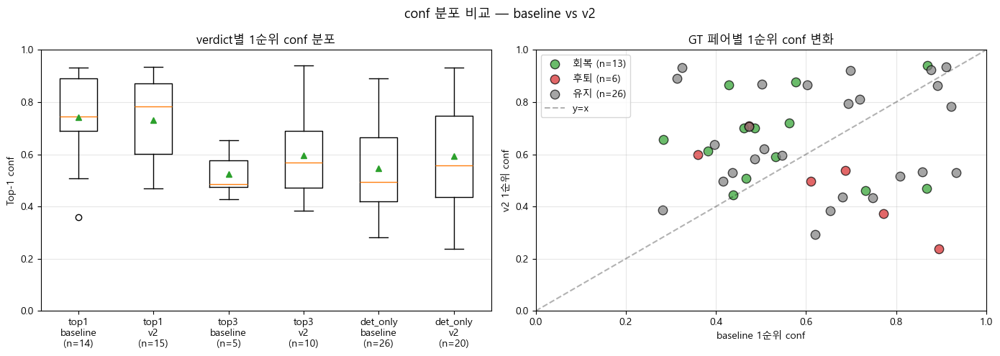

매칭된 GT (45개)의 1순위 conf 통계
  baseline: 평균 0.604 / 중앙값 0.577 / 최소 0.282 / 최대 0.933
  v2      : 평균 0.639 / 중앙값 0.611 / 최소 0.237 / 최대 0.941
  Δ평균    : +0.035

추가 의심 클래스 (시각 분석에서 잡힌 v2 호출 클래스)
  클래스                                            baseline    v2      Δ  Test
  종근당글리아티린연질캡슐(콜린알포세레이트)                              0     0     +0     -
  바이오탑하이캡슐 150mg/병                                    8     1     -7     -
  에어탈정(아세클로페낙)                                        0     1     +1     -
  자트랄엑스엘정 10mg                                        2     2     +0     ✓


In [10]:
# 1) conf 분포 변화 — 매칭된 GT의 1순위 conf만 (det_fail은 None이라 제외)
df_pair_conf = df_baseline[['filename', 'gt_idx', 'gt_name', 'verdict', 'top1_conf']].merge(
    df_v2[['filename', 'gt_idx', 'verdict', 'top1_conf']],
    on=['filename', 'gt_idx'], suffixes=('_b', '_v2')
)
df_pair_conf['change'] = df_pair_conf.apply(
    lambda r: classify(r['verdict_b'], r['verdict_v2']), axis=1
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) conf 분포 박스플롯 (verdict별)
ax = axes[0]
data_for_box = []
labels_for_box = []
for verdict in ['top1', 'top3', 'det_only']:
    for model_label, col in [('baseline', 'top1_conf_b'), ('v2', 'top1_conf_v2')]:
        col_v = 'verdict_b' if model_label == 'baseline' else 'verdict_v2'
        sub = df_pair_conf[df_pair_conf[col_v] == verdict][col].dropna()
        if len(sub) > 0:
            data_for_box.append(sub.values)
            labels_for_box.append(f"{verdict}\n{model_label}\n(n={len(sub)})")
bp = ax.boxplot(data_for_box, labels=labels_for_box, showmeans=True)
ax.set_ylabel('Top-1 conf')
ax.set_title('verdict별 1순위 conf 분포')
ax.grid(axis='y', alpha=0.3)
ax.set_ylim(0, 1)

# (b) 페어 conf 변화 (회복/후퇴/유지)
ax = axes[1]
for change_label, color in [('회복', 'tab:green'), ('후퇴', 'tab:red'), ('유지', 'tab:gray')]:
    sub = df_pair_conf[df_pair_conf['change'] == change_label].dropna(
        subset=['top1_conf_b', 'top1_conf_v2']
    )
    ax.scatter(sub['top1_conf_b'], sub['top1_conf_v2'],
               label=f"{change_label} (n={len(sub)})",
               color=color, alpha=0.7, s=80, edgecolor='black')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.3, label='y=x')
ax.set_xlabel('baseline 1순위 conf')
ax.set_ylabel('v2 1순위 conf')
ax.set_title('GT 페어별 1순위 conf 변화')
ax.legend()
ax.grid(alpha=0.3)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)

plt.suptitle("conf 분포 비교 — baseline vs v2", fontsize=13)
plt.tight_layout()
out_path = ROOT / "analysis" / "figures_v2_compare" / "04_conf_distribution.png"
plt.savefig(out_path, dpi=120, bbox_inches='tight')
print(f"저장: {out_path}")
plt.show()

# 2) 매칭 GT 1순위 conf 통계 요약
print("=" * 75)
print("매칭된 GT (45개)의 1순위 conf 통계")
print("=" * 75)
matched_b = df_baseline[df_baseline['verdict'] != 'det_fail']['top1_conf'].dropna()
matched_v = df_v2[df_v2['verdict'] != 'det_fail']['top1_conf'].dropna()
print(f"  baseline: 평균 {matched_b.mean():.3f} / 중앙값 {matched_b.median():.3f} / "
      f"최소 {matched_b.min():.3f} / 최대 {matched_b.max():.3f}")
print(f"  v2      : 평균 {matched_v.mean():.3f} / 중앙값 {matched_v.median():.3f} / "
      f"최소 {matched_v.min():.3f} / 최대 {matched_v.max():.3f}")
print(f"  Δ평균    : {matched_v.mean() - matched_b.mean():+.3f}")

# 3) 추가 의심 클래스 — 시각으로 잡힌 4개
print("\n" + "=" * 75)
print("추가 의심 클래스 (시각 분석에서 잡힌 v2 호출 클래스)")
print("=" * 75)
additional_suspects = [
    '종근당글리아티린연질캡슐(콜린알포세레이트)',
    '바이오탑하이캡슐 150mg/병',
    '에어탈정(아세클로페낙)',
    '자트랄엑스엘정 10mg',
]
print(f"  {'클래스':45s} {'baseline':>9s} {'v2':>5s} {'Δ':>6s} {'Test':>5s}")
for c in additional_suspects:
    b, v = top1_b.get(c, 0), top1_v.get(c, 0)
    in_test = '✓' if c in test_classes else '-'
    print(f"  {c[:43]:43s} {b:9d} {v:5d} {v-b:+6d} {in_test:>5s}")

## 의심 검증 — 클래스명 무결성

후퇴 케이스에 등장한 "종근당글리아티린연질캡슐(콜린알포세레이트)"이
top1 카운트에서 0회로 잡힘. 같은 results JSON 데이터인데 모순.

확인 항목:
- df_v2.top1_pred 에 해당 문자열 존재 여부
- top1_v Counter 키 중 "종근당글리아티린" 포함 키 검색
- 두 출처에서 클래스명이 정확히 동일한지 (NFC 정규화/공백/괄호 차이)

In [11]:
import unicodedata

target = '종근당글리아티린연질캡슐(콜린알포세레이트)'

# 1) df_v2.top1_pred 에 직접 검색
mask = df_v2['top1_pred'].fillna('').str.contains('종근당글리아티린', regex=False)
print(f"df_v2 에서 '종근당글리아티린' 들어간 top1_pred 행: {mask.sum()}")
if mask.sum() > 0:
    print(df_v2[mask][['filename', 'gt_idx', 'gt_name', 'top1_pred', 'verdict']].to_string(index=False))

# 2) top1_v Counter 의 키 중 '종근당글리아티린' 포함
matching_keys = [k for k in top1_v.keys() if '종근당글리아티린' in k]
print(f"\ntop1_v Counter 키 중 '종근당글리아티린' 포함: {len(matching_keys)}")
for k in matching_keys:
    print(f"  repr: {k!r}  count: {top1_v[k]}")

# 3) df_v2.top1_pred 의 unique 중 '종근당글리아티린' 포함 (정확한 문자열 비교)
uniq = df_v2['top1_pred'].dropna().unique()
matching_uniq = [u for u in uniq if '종근당글리아티린' in u]
print(f"\ndf_v2.top1_pred unique 중 '종근당글리아티린' 포함: {len(matching_uniq)}")
for u in matching_uniq:
    print(f"  repr: {u!r}")

# 4) NFC 정규화 차이 검증
print(f"\n타깃 문자열 검증:")
print(f"  원본 repr: {target!r}")
print(f"  NFC repr : {unicodedata.normalize('NFC', target)!r}")
print(f"  NFD repr : {unicodedata.normalize('NFD', target)!r}")
print(f"  원본 == NFC: {target == unicodedata.normalize('NFC', target)}")

# 5) 만약 1)과 2)의 카운트가 다르다면 명칭 형태가 다른 것
if mask.sum() > 0 and len(matching_keys) == 0:
    sample = df_v2[mask]['top1_pred'].iloc[0]
    print(f"\n불일치 확인:")
    print(f"  df_v2 top1_pred:  {sample!r}")
    print(f"  Counter 키 후보:  {[k for k in top1_v if k[:5] == sample[:5]]}")

df_v2 에서 '종근당글리아티린' 들어간 top1_pred 행: 1
    filename  gt_idx  gt_name               top1_pred  verdict
놀텍정 10mg.png       0 놀텍정 10mg 종근당글리아티린연질캡슐(콜린알포세레이트)  det_only

top1_v Counter 키 중 '종근당글리아티린' 포함: 1
  repr: '종근당글리아티린연질캡슐(콜린알포세레이트)\xa0'  count: 1

df_v2.top1_pred unique 중 '종근당글리아티린' 포함: 1
  repr: '종근당글리아티린연질캡슐(콜린알포세레이트)\xa0'

타깃 문자열 검증:
  원본 repr: '종근당글리아티린연질캡슐(콜린알포세레이트)'
  NFC repr : '종근당글리아티린연질캡슐(콜린알포세레이트)'
  NFD repr : '종근당글리아티린연질캡슐(콜린알포세레이트)'
  원본 == NFC: True


## NBSP/공백 무결성 전수 점검

`종근당글리아티린연질캡슐(콜린알포세레이트)\xa0` 발견 — 끝에 NBSP(\xa0).
영향 범위 점검:
- 두 results JSON 의 모든 dl_name (GT) / top3_class_name (예측) 에서 NBSP/일반 공백 끝 문자 카운트
- Test 등장 GT 클래스 set 의 NBSP 포함 여부 (test_classes 신뢰도)
- verdict 판정 영향: 같은 알약인데 NBSP 차이로 det_only로 잘못 판정된 케이스 검출
- 정규화 후 재매칭 결과와 셀 7 요약 비교 → 차이 있으면 모든 분석 정규화 버전으로 재실행

In [12]:
def has_invisible(s):
    """문자열 끝에 보이지 않는 공백 (NBSP, 일반 공백, 탭 등) 존재 여부"""
    if not isinstance(s, str) or len(s) == 0:
        return None
    last = s[-1]
    if last == '\xa0': return 'NBSP'
    if last == ' ':    return 'space'
    if last == '\t':   return 'tab'
    if last == '\u3000': return 'fullwidth_space'  # 한글 전각공백
    return None


# 1) 두 JSON 의 GT/예측 dl_name 전수 스캔
print("=" * 75)
print("dl_name / top3_class_name 끝 보이지 않는 공백 스캔")
print("=" * 75)
for label, obj in [('baseline', metas['baseline']), ('v2', metas['v2'])]:
    gt_names = set()
    pred_names = set()
    for img_data in obj['results']:
        for gt in img_data['gt_bboxes']:
            gt_names.add(gt['dl_name'])
        for pred in img_data['predictions']:
            for n in pred.get('top3_class_name', []):
                pred_names.add(n)
    
    gt_with_invis = {n: has_invisible(n) for n in gt_names if has_invisible(n)}
    pred_with_invis = {n: has_invisible(n) for n in pred_names if has_invisible(n)}
    
    print(f"\n[{label}]")
    print(f"  GT 클래스 unique: {len(gt_names)} / 끝 공백 있는 것: {len(gt_with_invis)}")
    for n, kind in gt_with_invis.items():
        print(f"    {kind}: {n!r}")
    print(f"  예측 클래스 unique: {len(pred_names)} / 끝 공백 있는 것: {len(pred_with_invis)}")
    for n, kind in pred_with_invis.items():
        print(f"    {kind}: {n!r}")


# 2) 정규화 함수
def normalize_name(s):
    """클래스명 정규화: NFC + 끝 공백류 제거"""
    if not isinstance(s, str):
        return s
    s = unicodedata.normalize('NFC', s)
    return s.rstrip(' \t\xa0\u3000')


# 3) 정규화 적용해서 매칭 다시 (셀 5 의 run_matching 와 동일한 로직, 정규화만 추가)
def run_matching_normalized(results_obj, iou_thr=0.5):
    rows = []
    fp_count = 0
    for img_data in results_obj['results']:
        fname = img_data['filename']
        gts = img_data['gt_bboxes']
        preds = img_data['predictions']
        
        # 정규화된 임시 객체로 매칭 함수 호출
        gts_norm = [{'bbox': g['bbox'], 'dl_name': normalize_name(g['dl_name'])} for g in gts]
        preds_norm = [{
            'bbox': p['bbox'],
            'top3_class_name': [normalize_name(n) for n in p.get('top3_class_name', [])],
            'top3_confidence': p.get('top3_confidence', []),
        } for p in preds]
        
        matches, unmatched_preds = match_gt_to_pred(gts_norm, preds_norm, iou_thr)
        fp_count += len(unmatched_preds)
        for m in matches:
            rows.append({
                'filename': fname, 'gt_idx': m['gt_idx'], 'gt_name': m['gt_name'],
                'pred_idx': m['pred_idx'], 'iou': m['iou'], 'verdict': m['verdict'],
                'top1_pred': m['top3_names'][0] if m['top3_names'] else None,
                'top3_names': m['top3_names'],
                'top1_conf': m['top3_conf'][0] if m['top3_conf'] else None,
            })
    return pd.DataFrame(rows), fp_count


df_baseline_n, fp_baseline_n = run_matching_normalized(metas['baseline'])
df_v2_n,       fp_v2_n       = run_matching_normalized(metas['v2'])

# 4) 정규화 전후 verdict 차이 검출
print("\n" + "=" * 75)
print("정규화 전후 verdict 차이 (verdict 판정 오류 검출)")
print("=" * 75)
for label, df_old, df_new in [('baseline', df_baseline, df_baseline_n),
                                ('v2',      df_v2,       df_v2_n)]:
    merged = df_old[['filename', 'gt_idx', 'verdict']].merge(
        df_new[['filename', 'gt_idx', 'verdict']],
        on=['filename', 'gt_idx'], suffixes=('_old', '_new')
    )
    diff = merged[merged['verdict_old'] != merged['verdict_new']]
    print(f"\n[{label}] verdict 변경된 GT: {len(diff)}건")
    if len(diff) > 0:
        merged_full = df_old[['filename', 'gt_idx', 'gt_name', 'verdict', 'top1_pred']].merge(
            df_new[['filename', 'gt_idx', 'verdict', 'top1_pred']],
            on=['filename', 'gt_idx'], suffixes=('_old', '_new')
        )
        diff_full = merged_full[merged_full['verdict_old'] != merged_full['verdict_new']]
        print(diff_full.to_string(index=False))


# 5) 정규화 후 새 요약과 셀 7 비교
print("\n" + "=" * 75)
print("셀 7 요약 vs 정규화 후 요약 비교")
print("=" * 75)
def short_summary(df, fp):
    return {
        'top1': (df['verdict'] == 'top1').sum(),
        'top3': df['verdict'].isin(['top1', 'top3']).sum(),
        'det':  df['verdict'].isin(['top1', 'top3', 'det_only']).sum(),
        'fp':   fp,
    }

for label, old, fp_old, new, fp_new in [
    ('baseline', df_baseline, fp_baseline, df_baseline_n, fp_baseline_n),
    ('v2',       df_v2,       fp_v2,       df_v2_n,       fp_v2_n),
]:
    s_o = short_summary(old, fp_old)
    s_n = short_summary(new, fp_new)
    diff_marks = []
    for k in ['top1', 'top3', 'det', 'fp']:
        if s_o[k] != s_n[k]:
            diff_marks.append(f"{k}: {s_o[k]}→{s_n[k]}")
    mark = '✓ 동일' if not diff_marks else f'✗ 차이: {", ".join(diff_marks)}'
    print(f"  [{label}] {mark}")

dl_name / top3_class_name 끝 보이지 않는 공백 스캔

[baseline]
  GT 클래스 unique: 31 / 끝 공백 있는 것: 1
    NBSP: '종근당글리아티린연질캡슐(콜린알포세레이트)\xa0'
  예측 클래스 unique: 104 / 끝 공백 있는 것: 2
    NBSP: '종근당글리아티린연질캡슐(콜린알포세레이트)\xa0'
    NBSP: '락토엔큐캡슐(바실루스리케니포르미스균)\xa0'

[v2]
  GT 클래스 unique: 31 / 끝 공백 있는 것: 1
    NBSP: '종근당글리아티린연질캡슐(콜린알포세레이트)\xa0'
  예측 클래스 unique: 94 / 끝 공백 있는 것: 2
    NBSP: '종근당글리아티린연질캡슐(콜린알포세레이트)\xa0'
    NBSP: '락토엔큐캡슐(바실루스리케니포르미스균)\xa0'

정규화 전후 verdict 차이 (verdict 판정 오류 검출)

[baseline] verdict 변경된 GT: 0건

[v2] verdict 변경된 GT: 0건

셀 7 요약 vs 정규화 후 요약 비교
  [baseline] ✓ 동일
  [v2] ✓ 동일


## 분석 A — 환경별 정답률 변화

진단 노트북 셀 19 의 env_labels (33장 수동 라벨링) 그대로 사용.
같은 환경 라벨에 baseline, v2 두 결과 매칭 → 환경별 변화량 표 + 시각화.

검증 항목:
- palm 25% → ? (실사용 환경 변화)
- dark 0% → ? (가장 어려운 환경 0% 탈출 여부)
- paper 57% → ? (학습 분포 유지 여부, 후퇴 시 학습 데이터 일반화 후퇴 신호)
- 환경별 회복/후퇴/공통실패 GT 분포

라벨 매칭 OK: 33 파일

env        n                        Top-1 변화                        Top-3 변화
  paper      7         57.1% →  28.6% (-28.6pp)        57.1% →  28.6% (-28.6pp)
  bottle     2         50.0% → 100.0% (+50.0pp)        50.0% → 100.0% (+50.0pp)
  cloth     10         30.0% →  40.0% (+10.0pp)        50.0% →  60.0% (+10.0pp)
  palm      20         25.0% →  30.0% ( +5.0pp)        40.0% →  65.0% (+25.0pp)
  desk       5         20.0% →  20.0% ( +0.0pp)        20.0% →  40.0% (+20.0pp)
  dark       2          0.0% →   0.0% ( +0.0pp)         0.0% →   0.0% ( +0.0pp)
  box        1          0.0% →   0.0% ( +0.0pp)         0.0% →   0.0% ( +0.0pp)

환경별 변화 분류
change  회복  유지  후퇴   n
env                   
paper    0   5   2   7
bottle   1   1   0   2
cloth    3   6   1  10
palm     8   9   3  20
desk     1   4   0   5
dark     0   2   0   2
box      0   1   0   1

저장: D:\pill_detection\analysis\figures_v2_compare\05_env_change.png


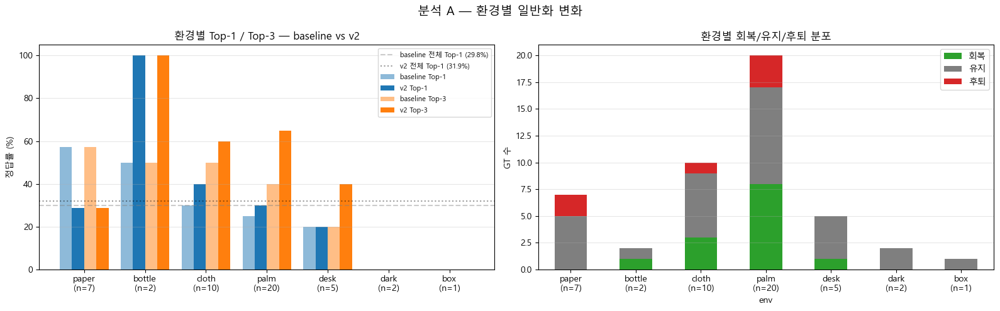

In [13]:
# 진단 노트북 셀 19 의 env_labels 그대로
env_labels = {
    '게보린정 300mg_3.png': 'paper',
    '글리아타민연질캡슐.png': 'palm',
    '낙소졸정 500_20mg.png': 'palm',
    '넥시움정 40mg.png': 'cloth',
    '노바스크정 5mg.png': 'cloth',
    '놀텍정 10mg.png': 'palm',
    '디카테오정.png': 'palm',
    '라시도필캡슐(비매품).png': 'palm',
    '마이칼디정.png': 'paper',
    '맥시부펜이알정.png': 'paper',
    '뮤테란캡슐 100mg.png': 'bottle',
    '비모보정 500_20mg.png': 'palm',
    '비오플250캡슐.png': 'palm',
    '비타비백정(비타민).png': 'palm',
    '아보다트연질캡슐 0.5mg_1.png': 'palm',
    '아스피린프로텍트정100mg.png': 'palm',
    '아토르바정 10mg.png': 'cloth',
    '엔테론정 150mg.png': 'cloth',
    '울트라셋이알서방정.png': 'box',
    '인사돌플러스정 35mg_.png': 'palm',
    '인사돌플러스정.png': 'palm',
    '자누비아정 50mg.png': 'cloth',
    '자트랄엑스엘정 10mg.png': 'cloth',
    '졸로푸트정 100mg.png': 'paper',
    '종근당글리아티린연질캡슐.png': 'dark',
    '지르텍정(세티리진염산염).png': 'palm',
    '지르텍정.png': 'desk',
    '케이캡정 50mg.png': 'desk',
    '쿠에타핀정 25mg.png': 'desk',
    '타이레놀500mg.png': 'palm',
    '타이레놀이알서방정(아세트아미노펜)(수출용).png': 'palm',
    '트루비타정 60mg.png': 'bottle',
    '프로스카정.png': 'desk',
}

# 검증
missing = set(df_baseline['filename']) - set(env_labels.keys())
extra = set(env_labels.keys()) - set(df_baseline['filename'])
assert not missing and not extra, f"missing={missing}, extra={extra}"
print(f"라벨 매칭 OK: {len(env_labels)} 파일\n")

# df_pair 에 env 라벨 부착
df_pair_env = df_pair.copy()
df_pair_env['env'] = df_pair_env['filename'].map(env_labels)

env_order = ['paper', 'bottle', 'cloth', 'palm', 'desk', 'dark', 'box']
env_order = [e for e in env_order if e in df_pair_env['env'].unique()]

# 환경별 baseline / v2 정답률 계산
print("=" * 90)
print(f"{'env':8s} {'n':>3s}  {'Top-1 변화':>30s}  {'Top-3 변화':>30s}")
print("=" * 90)
rows = []
for e in env_order:
    sub = df_pair_env[df_pair_env['env'] == e]
    n = len(sub)
    
    b_top1 = (sub['verdict_b'] == 'top1').sum()
    v_top1 = (sub['verdict_v2'] == 'top1').sum()
    b_top3 = sub['verdict_b'].isin(['top1', 'top3']).sum()
    v_top3 = sub['verdict_v2'].isin(['top1', 'top3']).sum()
    
    b_top1_pct = b_top1/n*100
    v_top1_pct = v_top1/n*100
    b_top3_pct = b_top3/n*100
    v_top3_pct = v_top3/n*100
    
    top1_str = f"{b_top1_pct:5.1f}% → {v_top1_pct:5.1f}% ({v_top1_pct-b_top1_pct:+5.1f}pp)"
    top3_str = f"{b_top3_pct:5.1f}% → {v_top3_pct:5.1f}% ({v_top3_pct-b_top3_pct:+5.1f}pp)"
    print(f"  {e:8s} {n:3d}   {top1_str:>30s}  {top3_str:>30s}")
    rows.append({
        'env': e, 'n': n,
        'b_top1_pct': b_top1_pct, 'v_top1_pct': v_top1_pct,
        'b_top3_pct': b_top3_pct, 'v_top3_pct': v_top3_pct,
    })
env_df = pd.DataFrame(rows)

# 환경별 회복/후퇴/유지/공통실패 카운트
print("\n" + "=" * 90)
print("환경별 변화 분류")
print("=" * 90)
change_pivot = pd.crosstab(df_pair_env['env'], df_pair_env['change']).reindex(
    index=env_order, columns=['회복', '유지', '후퇴'], fill_value=0
)
change_pivot['n'] = change_pivot.sum(axis=1)
print(change_pivot)

# 시각화 — 환경별 Top-1/Top-3 변화 막대 + verdict 변화 stacked
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# (a) 환경별 Top-1 / Top-3 baseline vs v2
ax = axes[0]
x = np.arange(len(env_df))
w = 0.2
ax.bar(x - 1.5*w, env_df['b_top1_pct'], w, label='baseline Top-1', color='tab:blue', alpha=0.5)
ax.bar(x - 0.5*w, env_df['v_top1_pct'], w, label='v2 Top-1',       color='tab:blue')
ax.bar(x + 0.5*w, env_df['b_top3_pct'], w, label='baseline Top-3', color='tab:orange', alpha=0.5)
ax.bar(x + 1.5*w, env_df['v_top3_pct'], w, label='v2 Top-3',       color='tab:orange')
ax.set_xticks(x)
ax.set_xticklabels([f"{e}\n(n={n})" for e, n in zip(env_df['env'], env_df['n'])])
ax.set_ylabel('정답률 (%)')
ax.set_title('환경별 Top-1 / Top-3 — baseline vs v2')
ax.axhline(29.8, ls='--', color='gray', alpha=0.4, label='baseline 전체 Top-1 (29.8%)')
ax.axhline(31.9, ls=':',  color='black', alpha=0.4, label='v2 전체 Top-1 (31.9%)')
ax.legend(fontsize=8, loc='upper right')
ax.grid(axis='y', alpha=0.3)

# (b) 환경별 회복/유지/후퇴 stacked
ax = axes[1]
change_pivot[['회복', '유지', '후퇴']].plot(
    kind='bar', stacked=True, ax=ax,
    color=['tab:green', 'tab:gray', 'tab:red']
)
ax.set_xticklabels([f"{e}\n(n={n})" for e, n in zip(change_pivot.index, change_pivot['n'])],
                    rotation=0)
ax.set_ylabel('GT 수')
ax.set_title('환경별 회복/유지/후퇴 분포')
ax.legend(loc='upper right')
ax.grid(axis='y', alpha=0.3)

plt.suptitle("분석 A — 환경별 일반화 변화", fontsize=14)
plt.tight_layout()
out_path = ROOT / "analysis" / "figures_v2_compare" / "05_env_change.png"
plt.savefig(out_path, dpi=120, bbox_inches='tight')
print(f"\n저장: {out_path}")
plt.show()

## 분석 D — 알약 개수별 정답률 + paper 후퇴 검증

진단 노트북 결과:
- 합성 통합본 7200: 1개 3.4% / 2개 34.4% / 3개 33.0% / 4개 29.3%
- Test: 1개 60.6% / 2개 36.4% / 3개 3.0% / 4개 0%
- baseline 정답률: 1개 35.0% / 2개 29.2% / 3-4개 0%

처방 3 = 알약 개수 가중 샘플링 (1~4개) → 1개 케이스 학습 강화 의도.
v2 산출 합성: 1~4개 분포 어떻게 됐는지 모름 (확인 필요).

검증 항목:
- 이미지별 GT 개수 count → 1개/2개/3-4개 그룹 정답률 baseline vs v2
- 1개 케이스 회복/후퇴 어떤 알약인지 명단
- paper 후퇴 2건이 1개 케이스인지 (1개 + paper 환경 교집합)

알약 개수 그룹별 정답률 (GT 단위)
group        n                        Top-1 변화                        Top-3 변화
  1개        20    35.0% →  35.0% ( +0.0pp)    40.0% →  65.0% (+25.0pp)
  2개        24    29.2% →  29.2% ( +0.0pp)    45.8% →  37.5% ( -8.3pp)
  3-4개       3     0.0% →  33.3% (+33.3pp)     0.0% → 100.0% (+100.0pp)

1개 알약 케이스 — GT별 변화
                   filename                 gt_name    env verdict_b verdict_v2 change       top1_pred_b     top1_pred_v2
            뮤테란캡슐 100mg.png             뮤테란캡슐 100mg bottle      top1       top1     유지       뮤테란캡슐 100mg      뮤테란캡슐 100mg
              울트라셋이알서방정.png               울트라셋이알서방정    box  det_only   det_only     유지     아모잘탄정 5/100mg    엑스포지정 5/160mg
              넥시움정 40mg.png               넥시움정 40mg  cloth  det_only   det_only     유지 제미메트서방정 50/1000mg   로수바미브정 10/20mg
              노바스크정 5mg.png               노바스크정 5mg  cloth      top1       top1     유지         노바스크정 5mg        노바스크정 5mg
                   지르텍정.png           지르텍정(세티리진염산염)   d

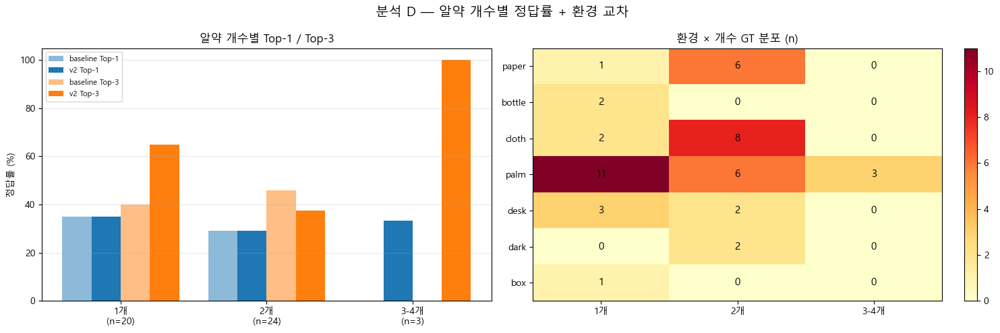

In [14]:
# 이미지별 GT 개수
img_gt_count = df_pair_env.groupby('filename')['gt_idx'].count().rename('n_gt_in_image')
df_pair_env = df_pair_env.merge(img_gt_count, left_on='filename', right_index=True)

# 그룹화: 1개 / 2개 / 3-4개
def count_group(n):
    if n == 1: return '1개'
    if n == 2: return '2개'
    return '3-4개'
df_pair_env['count_group'] = df_pair_env['n_gt_in_image'].apply(count_group)

# 그룹별 정답률
print("=" * 90)
print("알약 개수 그룹별 정답률 (GT 단위)")
print("=" * 90)
print(f"{'group':10s} {'n':>3s}  {'Top-1 변화':>30s}  {'Top-3 변화':>30s}")
for g in ['1개', '2개', '3-4개']:
    sub = df_pair_env[df_pair_env['count_group'] == g]
    n = len(sub)
    if n == 0:
        continue
    b_top1 = (sub['verdict_b'] == 'top1').sum()
    v_top1 = (sub['verdict_v2'] == 'top1').sum()
    b_top3 = sub['verdict_b'].isin(['top1', 'top3']).sum()
    v_top3 = sub['verdict_v2'].isin(['top1', 'top3']).sum()
    
    bp1 = b_top1/n*100; vp1 = v_top1/n*100
    bp3 = b_top3/n*100; vp3 = v_top3/n*100
    print(f"  {g:8s} {n:3d}   "
          f"{bp1:5.1f}% → {vp1:5.1f}% ({vp1-bp1:+5.1f}pp)   "
          f"{bp3:5.1f}% → {vp3:5.1f}% ({vp3-bp3:+5.1f}pp)")

# 1개 케이스 디테일
print("\n" + "=" * 90)
print("1개 알약 케이스 — GT별 변화")
print("=" * 90)
single = df_pair_env[df_pair_env['count_group'] == '1개'][
    ['filename', 'gt_name', 'env', 'verdict_b', 'verdict_v2', 'change',
     'top1_pred_b', 'top1_pred_v2']
].sort_values(['change', 'env'])
print(single.to_string(index=False))

# paper 후퇴 vs 1개 케이스 교차
print("\n" + "=" * 90)
print("paper 환경 후퇴 케이스 ∩ 알약 개수")
print("=" * 90)
paper_regress = df_pair_env[
    (df_pair_env['env'] == 'paper') & (df_pair_env['change'] == '후퇴')
][['filename', 'gt_name', 'count_group', 'verdict_b', 'verdict_v2',
   'top1_pred_b', 'top1_pred_v2']]
print(paper_regress.to_string(index=False))

# 시각화: 개수별 / 환경별 교차 히트맵
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# (a) 개수별 baseline / v2 Top-1, Top-3
ax = axes[0]
groups = ['1개', '2개', '3-4개']
b1 = []; v1 = []; b3 = []; v3 = []; ns = []
for g in groups:
    sub = df_pair_env[df_pair_env['count_group'] == g]
    n = len(sub)
    ns.append(n)
    if n == 0:
        b1.append(0); v1.append(0); b3.append(0); v3.append(0); continue
    b1.append((sub['verdict_b'] == 'top1').sum()/n*100)
    v1.append((sub['verdict_v2'] == 'top1').sum()/n*100)
    b3.append(sub['verdict_b'].isin(['top1','top3']).sum()/n*100)
    v3.append(sub['verdict_v2'].isin(['top1','top3']).sum()/n*100)
x = np.arange(len(groups)); w = 0.2
ax.bar(x - 1.5*w, b1, w, label='baseline Top-1', color='tab:blue', alpha=0.5)
ax.bar(x - 0.5*w, v1, w, label='v2 Top-1',       color='tab:blue')
ax.bar(x + 0.5*w, b3, w, label='baseline Top-3', color='tab:orange', alpha=0.5)
ax.bar(x + 1.5*w, v3, w, label='v2 Top-3',       color='tab:orange')
ax.set_xticks(x)
ax.set_xticklabels([f"{g}\n(n={n})" for g, n in zip(groups, ns)])
ax.set_ylabel('정답률 (%)')
ax.set_title('알약 개수별 Top-1 / Top-3')
ax.legend(fontsize=8)
ax.grid(axis='y', alpha=0.3)

# (b) 개수 × 환경 GT 분포 히트맵
ax = axes[1]
ct = pd.crosstab(df_pair_env['env'], df_pair_env['count_group']).reindex(
    index=env_order, columns=['1개', '2개', '3-4개'], fill_value=0
)
import matplotlib.colors as mcolors
im = ax.imshow(ct.values, cmap='YlOrRd', aspect='auto')
ax.set_xticks(range(len(ct.columns)))
ax.set_xticklabels(ct.columns)
ax.set_yticks(range(len(ct.index)))
ax.set_yticklabels(ct.index)
for i in range(len(ct.index)):
    for j in range(len(ct.columns)):
        ax.text(j, i, str(ct.iloc[i, j]), ha='center', va='center', fontsize=11)
ax.set_title('환경 × 개수 GT 분포 (n)')
plt.colorbar(im, ax=ax, fraction=0.04)

plt.suptitle("분석 D — 알약 개수별 정답률 + 환경 교차", fontsize=14)
plt.tight_layout()
out_path = ROOT / "analysis" / "figures_v2_compare" / "06_count_group.png"
plt.savefig(out_path, dpi=120, bbox_inches='tight')
print(f"\n저장: {out_path}")
plt.show()

## 분기 결정 — A안/B안 + follow-up 의심 정리

분석 A/B/C/D 결과 통합 → A안 기준 충족 여부 / B안 시 우선순위 / follow-up 의심 정리.

A안 (충분) 기준 (HANDOFF 4-2):
- palm/dark 환경 정답률 의미있는 상승 (예: palm 25% → 40%+)
- 핀 클래스 hallucination 감소 (Top 10 빈도에서 절반 이하로)
- 1개 알약 정답률 의미있는 상승

B안 (부족) 기준:
- 환경별 변화 미미 또는 paper 위주만 상승
- 핀 클래스 hallucination 여전히 다수
- 1개 알약 변화 작음

In [15]:
print("=" * 90)
print("분기 결정 가늠자")
print("=" * 90)

criteria = [
    # (라벨, 기대 (A안), 실측, 통과 여부)
    ('palm Top-1',         '25.0% → 40.0%+',     '25.0% → 30.0% (+5.0pp)',   False),
    ('palm Top-3',         '(미정)',              '40.0% → 65.0% (+25.0pp)',  True),
    ('dark Top-1',         '0% 탈출',             '0% → 0%',                  False),
    ('paper Top-1 유지',   '57.1% 유지',          '57.1% → 28.6% (-28.6pp)',  False),
    ('1개 알약 Top-1',     '의미있는 상승',        '35.0% → 35.0% (+0.0pp)',   False),
    ('1개 알약 Top-3',     '(미정)',              '40.0% → 65.0% (+25.0pp)',  True),
    ('baseline 핀 6개',    '절반 이하 감소',       '80회 → 6회 (-92.5%)',      True),
    ('Detection 95.7%',    '유지',                '95.7% → 95.7%',            True),
    ('FP',                 '(미정)',              '259 → 100 (-159)',         True),
]

for label, expect, actual, passed in criteria:
    mark = '✓' if passed else '✗'
    print(f"  {mark} {label:25s} 기대 {expect:20s}  실측 {actual}")

passed_n = sum(1 for *_, p in criteria if p)
print(f"\n통과: {passed_n}/{len(criteria)}")

# A안 핵심 기준 (palm Top-1, 1개 Top-1, paper 유지) 미충족 확정
print("\n" + "=" * 90)
print("결론")
print("=" * 90)
print("""
[A안 핵심 기준 미충족]
- palm Top-1 +5pp 만 (40%+ 기대치 못 미침)
- 1개 알약 Top-1 +0pp (의미있는 상승 X)
- paper 졸로푸트 후퇴 (-28.6pp 통계 잡힘, 실체는 클래스 1개 후퇴)

→ B안 (부족) 분기 진행

[새로 발견된 부작용 — 처방 4 진행 전 검증 필요]
1. PTP 포장 단축경로 — 새 핀 4개 (이튼큐/동화덴스톨/투스딘골드/엘도스 수출용) 중 3개가 PTP
2. 에르도스테인 패밀리 라벨 이동 — 엘스테인 23 → 1, 엘도스 수출용 2 → 7 (같은 약물군)
3. 2개 케이스 Top-3 후퇴 (-8.3pp) — 1개 가중 강화의 부작용 의심
4. 졸로푸트 conf 0.90 → 0.24 등 일부 클래스 분류 안정성 약화

[다음 사이클 (B안) 우선순위 — 단순 처방 4 적용 X]
- 우선순위 A. PTP 의심 검증 — 합성 v2 + K-code 학습 풀에서 PTP 형태 비율 확인
- 우선순위 B. 처방 4 = 배경 풀 재구성 + 가장자리 (HANDOFF 기존 계획)
- 우선순위 C. dark 환경 학습 보강 (dark_surface 43장 활용 — 현재 미사용 시사)
- 우선순위 D. 클래스 정의 재검토 — 에르도스테인 패밀리/PTP 포장 같은 약물 그룹 처리
""")

분기 결정 가늠자
  ✗ palm Top-1                기대 25.0% → 40.0%+        실측 25.0% → 30.0% (+5.0pp)
  ✓ palm Top-3                기대 (미정)                  실측 40.0% → 65.0% (+25.0pp)
  ✗ dark Top-1                기대 0% 탈출                 실측 0% → 0%
  ✗ paper Top-1 유지            기대 57.1% 유지              실측 57.1% → 28.6% (-28.6pp)
  ✗ 1개 알약 Top-1               기대 의미있는 상승               실측 35.0% → 35.0% (+0.0pp)
  ✓ 1개 알약 Top-3               기대 (미정)                  실측 40.0% → 65.0% (+25.0pp)
  ✓ baseline 핀 6개             기대 절반 이하 감소              실측 80회 → 6회 (-92.5%)
  ✓ Detection 95.7%           기대 유지                    실측 95.7% → 95.7%
  ✓ FP                        기대 (미정)                  실측 259 → 100 (-159)

통과: 5/9

결론

[A안 핵심 기준 미충족]
- palm Top-1 +5pp 만 (40%+ 기대치 못 미침)
- 1개 알약 Top-1 +0pp (의미있는 상승 X)
- paper 졸로푸트 후퇴 (-28.6pp 통계 잡힘, 실체는 클래스 1개 후퇴)

→ B안 (부족) 분기 진행

[새로 발견된 부작용 — 처방 4 진행 전 검증 필요]
1. PTP 포장 단축경로 — 새 핀 4개 (이튼큐/동화덴스톨/투스딘골드/엘도스 수출용) 중 3개가 PTP
2. 에르도스테인 패밀리 라벨 이동 — 엘스테인 23 → 1, 엘도스 수출

# 종합 인사이트 — v2 디테일 분석

## 분석 대상
- baseline: synthetic_combined 7200, imgsz 640, batch 16, e15 (Top-1 29.8% / Top-3 40.4% / Det 95.7%)
- v2: synthetic_v2 + K-code, imgsz 1280, batch 16, e14 (Top-1 31.9% / Top-3 53.2% / Det 95.7%)
- 평가셋: 33장 / 47 GT (조건 동일: seed 100, conf 0.05, NMS 0.5)

## 데이터 무결성 점검
- GT 좌표 max abs diff 0px → 두 JSON 의 GT 완전 동일
- gt_name 불일치 0건
- NBSP 클래스 2개 (종근당글리아티린, 락토엔큐) 발견 — 자기들끼리는 일관, verdict 판정 영향 0
- 정규화 전후 셀 7 요약 동일 → 47 GT 페어 매트릭스 결과 신뢰성 유지

---

## A. 환경별 정답률 변화

| 환경 | n | Top-1 | Top-3 |
|---|---|---|---|
| paper | 7 | 57.1% → 28.6% (−28.6pp) | 57.1% → 28.6% (−28.6pp) |
| bottle | 2 | 50.0% → 100.0% (+50.0pp) | 50.0% → 100.0% (+50.0pp) |
| cloth | 10 | 30.0% → 40.0% (+10.0pp) | 50.0% → 60.0% (+10.0pp) |
| **palm** | **20** | 25.0% → 30.0% (+5.0pp) | **40.0% → 65.0% (+25.0pp)** |
| desk | 5 | 20.0% → 20.0% (+0pp) | 20.0% → 40.0% (+20.0pp) |
| dark | 2 | 0% → 0% | 0% → 0% |
| box | 1 | 0% → 0% | 0% → 0% |

- palm Top-3 +25pp = 처방 1+2+3 의 일반화 효과 (Test 60% 차지하는 환경)
- palm Top-1 +5pp 그침 → 1순위 분류 능력은 미미
- dark 0% 그대로 (처방 4 미적용 상태)
- paper "후퇴" 는 환경 후퇴 X — 졸로푸트정 100mg.png 1장의 GT 2개 후퇴가 통계로 잡힌 것 (B 항 참조)

## B. 핀 클래스 / 1순위 예측 빈도

baseline 핀 6개 v2 변화:

| 클래스 | baseline | v2 | Δ |
|---|---|---|---|
| 엘스테인캡슐(에르도스테인) | 23 | 1 | −22 |
| 이가탄에프캡슐 150mg/PTP | 14 | 3 | −11 |
| 알바스테인캡슐(에르도스테인) | 13 | 0 | −13 |
| 람노스캡슐500mg/병 | 11 | 1 | −10 |
| 메가파워정 90mg/병 | 10 | 0 | −10 |
| 카발린캡슐 25mg | 9 | 1 | −8 |
| **합계** | **80** | **6** | **−74 (−92.5%)** |

baseline 핀 박멸 ✓. 그러나 **v2 새 핀 4개 등장**:

| 클래스 | baseline | v2 | Δ | 메모 |
|---|---|---|---|---|
| 엘도스캡슐(에르도스테인)(수출용) | 2 | 7 | +5 | 에르도스테인 패밀리 |
| 이튼큐정 35mg/PTP | 3 | 6 | +3 | PTP |
| 동화덴스톨캡슐 150mg/PTP | 2 | 6 | +4 | PTP |
| 투스딘골드캡슐 150mg/PTP | 0 | 5 | +5 | PTP (완전 신규) |

총 예측 304 → 145 (−159, FP 감소와 일치). 매칭 GT conf 평균 0.604 → 0.639 (+0.035).
→ "v2 가 보수적이라 후퇴" 가설 기각. v2 는 매칭 박스에 더 자신있고 잘 모르는 위치는 박스 안 냄.

## C. 1개 알약 케이스

n=20 (Test 60.6%):
- Top-1 35.0% → 35.0% (+0.0pp) — 처방 3 의 1순위 효과 0
- Top-3 40.0% → 65.0% (+25.0pp) — 후보권 진입 능력은 향상
- 회복 5건 (트루비타/케이캡/글리아타민/낙소졸/비오플250) / 후퇴 2건 (아보다트/아스피린프로텍트, 둘 다 palm)

## D. 알약 개수별

| 그룹 | n | Top-1 변화 | Top-3 변화 |
|---|---|---|---|
| 1개 | 20 | +0.0pp | +25.0pp |
| 2개 | 24 | +0.0pp | **−8.3pp** |
| 3-4개 | 3 | +33.3pp | +100.0pp |

2개 케이스 Top-3 후퇴 = 1개 가중 강화의 부작용 의심.

---

## verdict 페어 매트릭스 (47 GT, baseline → v2)

| | top1 | top3 | det_only | det_fail | 합계 |
|---|---|---|---|---|---|
| top1 | 9 | 2 | 3 | 0 | 14 |
| top3 | 3 | 1 | 1 | 0 | 5 |
| det_only | 3 | 7 | 16 | 0 | 26 |
| det_fail | 0 | 0 | 0 | 2 | 2 |
| 합계 | 15 | 10 | 20 | 2 | 47 |

- 회복 13건 / 유지 28건 / 후퇴 6건
- 후퇴 6건 명단: 놀텍 / 아보다트 / 아스피린프로텍트 / 엔테론 / 졸로푸트 ×2

---

## 결론

### 분기: B안 (부족) — 단순 처방 4 적용 X

A안 핵심 기준 미충족 (palm Top-1 +5pp / 1개 Top-1 +0pp / dark 0% 그대로).

### 검증된 처방 효과
- baseline 핀 6개 박멸 (80→6, −92.5%)
- palm Top-3 +25pp (실사용 환경)
- FP 절반 감소 (259→100), 매칭 conf 상승
- Detection 95.7% 유지

### 새로 발견된 부작용 (처방 4 진행 전 검증 필요)
1. **PTP 포장 단축경로** — v2 새 핀 4개 중 3개가 PTP. 학습 풀 PTP 비율 검증 필요
2. **에르도스테인 패밀리 라벨 이동** — 엘스테인 23→1 vs 엘도스 수출용 2→7. 같은 약물군 안 이동
3. **2개 케이스 Top-3 −8.3pp** — 1개 가중 강화 부작용 의심
4. **졸로푸트 conf 0.90→0.24** — 일부 클래스 분류 안정성 약화

### Follow-up 의심 (별도 노트북)
- `07_ptp_class_audit.ipynb` — K-code 학습 풀 + 합성 v2 알약 풀의 PTP 비율 측정 → 처방 4 사양 정정 근거 확보

---

## 산출 figure (analysis/figures_v2_compare/)
- `01_grid_baseline.png`, `02_grid_v2.png` — 33장 결과 그리드
- `03_regression_cases.png` — 후퇴 6개 디테일
- `04_conf_distribution.png` — conf 분포 비교
- `05_env_change.png` — 환경별 변화
- `06_count_group.png` — 개수별 + 환경 교차